In [1]:
import pandas as pd
import numpy as np

In [2]:
import pandas as pd

customers = pd.DataFrame({
    'Customer_ID':[101,102,103,104,105,106,107,108],
    'Customer_Name':['Alice','Bob','Charlie','David','Eva','Frank','Grace','Helen'],
    'Region':['Asia','Europe','Asia','Africa','Europe','Asia','Africa','Europe'],
    'Age':[25,34,29,45,31,40,27,36]
})

customers

,Customer_ID,Customer_Name,Region,Age
0,101,Alice,Asia,25
1,102,Bob,Europe,34
2,103,Charlie,Asia,29
3,104,David,Africa,45
4,105,Eva,Europe,31
5,106,Frank,Asia,40
6,107,Grace,Africa,27
7,108,Helen,Europe,36


In [5]:
orders = pd.DataFrame({
    'Order_ID':[1,2,3,4,5,6,7,8,9,10,11,12],
    'Customer_ID':[101,101,102,103,103,104,105,106,106,107,108,108],
    'Product':['Laptop','Mouse','Keyboard','Laptop','Monitor','Laptop','Mouse','Keyboard','Monitor','Laptop','Mouse','Laptop'],
    'Category':['Electronics','Accessories','Accessories','Electronics','Electronics','Electronics','Accessories','Accessories','Electronics','Electronics','Accessories','Electronics'],
    'Sales_Channel':['Online','Offline','Online','Offline','Online','Online','Offline','Online','Offline','Offline','Online','Online'],
    'Quantity':[2,5,3,1,2,1,6,3,2,1,7,2],
    'Price':[800,25,50,850,300,900,20,60,350,950,30,870]
})

orders['Revenue']=orders['Quantity']*orders['Price']

orders

,Order_ID,Customer_ID,Product,Category,Sales_Channel,Quantity,Price,Revenue
0,1,101,Laptop,Electronics,Online,2,800,1600
1,2,101,Mouse,Accessories,Offline,5,25,125
2,3,102,Keyboard,Accessories,Online,3,50,150
3,4,103,Laptop,Electronics,Offline,1,850,850
4,5,103,Monitor,Electronics,Online,2,300,600
5,6,104,Laptop,Electronics,Online,1,900,900
6,7,105,Mouse,Accessories,Offline,6,20,120
7,8,106,Keyboard,Accessories,Online,3,60,180
8,9,106,Monitor,Electronics,Offline,2,350,700
9,10,107,Laptop,Electronics,Offline,1,950,950


In [7]:
payments = pd.DataFrame({
    'Order_ID':[1,2,3,4,5,6,7,8,9,10,11,12],
    'Payment_Method':['Card','UPI','Card','Cash','UPI','Card','Cash','Card','UPI','Cash','Card','UPI'],
    'Status':['Completed','Completed','Cancelled','Completed','Completed','Completed','Cancelled','Completed','Completed','Completed','Completed','Completed']
})

payments

,Order_ID,Payment_Method,Status
0,1,Card,Completed
1,2,UPI,Completed
2,3,Card,Cancelled
3,4,Cash,Completed
4,5,UPI,Completed
5,6,Card,Completed
6,7,Cash,Cancelled
7,8,Card,Completed
8,9,UPI,Completed
9,10,Cash,Completed


Q1

Find total Revenue by Region. * 3 ways

In [11]:
customers.head(2)

,Customer_ID,Customer_Name,Region,Age
0,101,Alice,Asia,25
1,102,Bob,Europe,34


In [13]:
orders.head(2)

,Order_ID,Customer_ID,Product,Category,Sales_Channel,Quantity,Price,Revenue
0,1,101,Laptop,Electronics,Online,2,800,1600
1,2,101,Mouse,Accessories,Offline,5,25,125


In [19]:
pd.merge(left=customers,right=orders,on='Customer_ID',how='inner').groupby('Region')['Revenue'].sum()

Region
Africa    1850
Asia      4055
Europe    2220
Name: Revenue, dtype: int64

In [27]:
pd.merge(left=customers,right=orders,on='Customer_ID',how='inner').groupby('Region')['Revenue'].agg('sum')

Region
Africa    1850
Asia      4055
Europe    2220
Name: Revenue, dtype: int64

In [29]:
pd.merge(left=customers,right=orders,on='Customer_ID',how='inner').groupby('Region').agg({'Revenue':['sum','mean']})

Revenue            
           sum        mean
Region                    
Africa    1850  925.000000
Asia      4055  675.833333
Europe    2220  555.000000

Q2

Find average Revenue by Product.

In [31]:
orders.groupby('Product')['Revenue'].mean()

Product
Keyboard     165.000000
Laptop      1208.000000
Monitor      650.000000
Mouse        151.666667
Name: Revenue, dtype: float64

In [33]:
orders.groupby('Product')['Revenue'].agg('mean')

Product
Keyboard     165.000000
Laptop      1208.000000
Monitor      650.000000
Mouse        151.666667
Name: Revenue, dtype: float64

In [35]:
orders.groupby('Product').agg({'Revenue': 'mean'})

,Revenue
Product,
Keyboard,165.000000
Laptop,1208.000000
Monitor,650.000000
Mouse,151.666667


In [37]:
orders.head(1)

,Order_ID,Customer_ID,Product,Category,Sales_Channel,Quantity,Price,Revenue
0,1,101,Laptop,Electronics,Online,2,800,1600


Q3

Find

Sum
Mean
Max
Min

Revenue by Category.

In [39]:
orders.groupby('Category')['Revenue'].agg(['sum','mean','max','min'])

,sum,mean,max,min
Category,,,,
Accessories,785,157.000000,210,120
Electronics,7340,1048.571429,1740,600


In [41]:
orders.groupby('Category').agg({'Revenue':['mean','sum','max','min']})

Revenue                 
                    mean   sum   max  min
Category                                 
Accessories   157.000000   785   210  120
Electronics  1048.571429  7340  1740  600

Q4

Find

Total Quantity
Average Quantity
Maximum Quantity

for each Sales Channel.

In [47]:
orders.head(1)

,Order_ID,Customer_ID,Product,Category,Sales_Channel,Quantity,Price,Revenue
0,1,101,Laptop,Electronics,Online,2,800,1600


In [51]:
orders.groupby('Sales_Channel')['Quantity'].agg(['sum',
                                                'mean',
                                                'max'])

,sum,mean,max
Sales_Channel,,,
Offline,15,3.000000,6
Online,20,2.857143,7


In [53]:
orders.groupby('Sales_Channel')['Quantity'] \
    .agg(['sum','mean','max']) \
    .rename(columns = {'sum':'total quantity', 'mean':'average quantity', 'max':'maximum quantity'})

,total quantity,average quantity,maximum quantity
Sales_Channel,,,
Offline,15,3.000000,6
Online,20,2.857143,7


Q5

Find total Revenue generated by each Customer.

In [63]:
pd.merge(left=customers,right=orders,on='Customer_ID',how='left').groupby('Customer_Name')['Revenue'].sum().sort_values(ascending=False)

Customer_Name
Helen      1950
Alice      1725
Charlie    1450
Grace       950
David       900
Frank       880
Bob         150
Eva         120
Name: Revenue, dtype: int64

<Axes: xlabel='Customer_Name'>

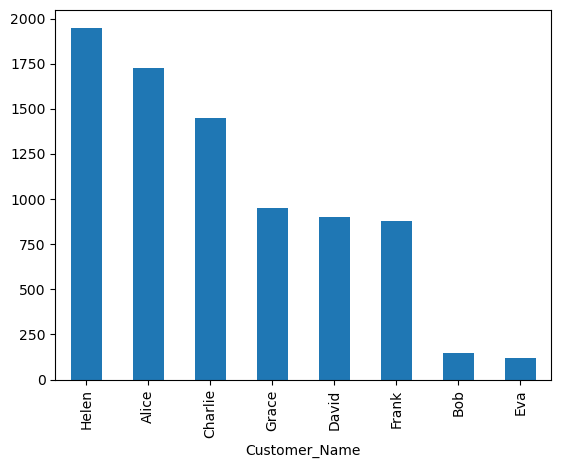

In [66]:
pd.merge(left=customers,right=orders,on='Customer_ID',how='left').groupby('Customer_Name')['Revenue'].sum().sort_values(ascending=False).plot(kind='bar')

Q6

Find

Revenue Sum
Revenue Mean
Revenue Std

for each Region.

In [69]:
customers.head(1)

,Customer_ID,Customer_Name,Region,Age
0,101,Alice,Asia,25


In [85]:
pd.merge(left=customers,right=orders,on='Customer_ID',how='left').groupby('Region')['Revenue'].agg(['sum','mean','std'])

,sum,mean,std
Region,,,
Africa,1850,925.000000,35.355339
Asia,4055,675.833333,536.660197
Europe,2220,555.000000,790.885580


In [93]:
pd.merge(left=customers,right=orders,on='Customer_ID',how='left').groupby('Region').agg(
                                                                    Revenue_Sum = ('Revenue','sum'),
                                                                    Revenue_mean = ('Revenue', 'mean'),
                                                                    Revenue_std = ('Revenue', 'std')
)

,Revenue_Sum,Revenue_mean,Revenue_std
Region,,,
Africa,1850,925.000000,35.355339
Asia,4055,675.833333,536.660197
Europe,2220,555.000000,790.885580


Q7

Find

Quantity Sum
Revenue Sum

for each Region.

In [101]:
pd.merge(left=customers,right=orders,on='Customer_ID',how='left').groupby('Region').agg({'Quantity':'sum',
                                                                                         'Revenue':'sum'}).sort_values(by=['Revenue','Quantity'], ascending=[False,True])

,Quantity,Revenue
Region,,
Asia,15,4055
Europe,18,2220
Africa,2,1850


<Axes: xlabel='Region'>

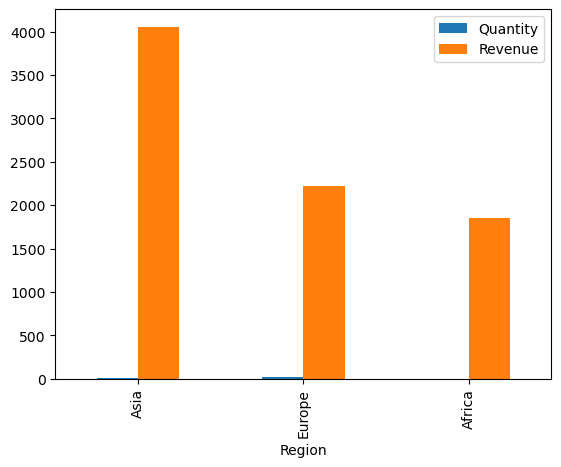

In [105]:
pd.merge(left=customers,right=orders,on='Customer_ID',how='left').groupby('Region').agg({'Quantity':'sum',
                                                                                         'Revenue':'sum'}).sort_values(by=['Revenue','Quantity'], ascending=[False,True]).plot(kind='bar')

In [107]:
orders.head(1)

,Order_ID,Customer_ID,Product,Category,Sales_Channel,Quantity,Price,Revenue
0,1,101,Laptop,Electronics,Online,2,800,1600


Q8

Find

Total Orders
Average Revenue

for each Product

In [113]:
orders.groupby('Product').agg({'Order_ID': 'count','Revenue':'mean'})

,Order_ID,Revenue
Product,,
Keyboard,2,165.000000
Laptop,5,1208.000000
Monitor,2,650.000000
Mouse,3,151.666667


In [115]:
orders.groupby('Product')[['Order_ID','Revenue']].agg(['count','mean'])

Order_ID           Revenue             
            count      mean   count         mean
Product                                         
Keyboard        2  5.500000       2   165.000000
Laptop          5  6.600000       5  1208.000000
Monitor         2  7.000000       2   650.000000
Mouse           3  6.666667       3   151.666667

Q9

Find top customer based on total Revenue.

In [118]:
pd.merge(left=customers,right=orders,on='Customer_ID',how='left').groupby('Customer_Name')['Revenue'].sum()

Customer_Name
Alice      1725
Bob         150
Charlie    1450
David       900
Eva         120
Frank       880
Grace       950
Helen      1950
Name: Revenue, dtype: int64

In [126]:
pd.merge(left=customers,right=orders,on='Customer_ID',how='left').groupby('Customer_Name').agg({'Revenue':'sum'}).head(1)

,Revenue
Customer_Name,
Alice,1725


## PIVOT TABLES

Q11

Average Revenue by Region.

In [140]:
pd.merge(left=customers,right=orders,on='Customer_ID',how='left').pivot_table(index='Region',values='Revenue',aggfunc='mean')

,Revenue
Region,
Africa,925.000000
Asia,675.833333
Europe,555.000000


Q12

Average Revenue by

Region × Sales Channel

In [142]:
orders.head(1)

,Order_ID,Customer_ID,Product,Category,Sales_Channel,Quantity,Price,Revenue
0,1,101,Laptop,Electronics,Online,2,800,1600


In [149]:
pd.merge(left=customers,right=orders,on='Customer_ID',how='left').pivot_table(values='Revenue',index='Region',columns='Sales_Channel',aggfunc='mean',margins=True)

Sales_Channel,Offline,Online,All
Region,,,
Africa,950.000000,900.000000,925.000000
Asia,558.333333,793.333333,675.833333
Europe,120.000000,700.000000,555.000000
All,549.000000,768.571429,677.083333


Q13

Total Revenue by

Category × Region

In [153]:
pd.merge(left=customers,right=orders,on='Customer_ID',how='left').pivot_table(index='Category',columns='Region',values='Revenue',aggfunc='sum',margins=True,fill_value=0)

Region,Africa,Asia,Europe,All
Category,,,,
Accessories,0,305,480,785
Electronics,1850,3750,1740,7340
All,1850,4055,2220,8125


Q15

Multiple aggregations

Sum

Mean

Max

of Revenue

by Region.

In [157]:
pd.merge(left=customers,right=orders,on='Customer_ID',how='left').pivot_table(index='Region',values='Revenue',aggfunc=['sum','mean','max'],margins=True,fill_value=0)

,sum,mean,max
,Revenue,Revenue,Revenue
Region,,,
Africa,1850,925.000000,950
Asia,4055,675.833333,1600
Europe,2220,555.000000,1740
All,8125,677.083333,1740


In [9]:
#cross tab

PART 3 — Crosstab

Q16

Count customers in every Region.

In [19]:
pd.crosstab(index=customers['Region'],columns='Count')

col_0,Count
Region,
Africa,2
Asia,3
Europe,3


In [21]:
customers['Region'].value_counts()

Region
Asia      3
Europe    3
Africa    2
Name: count, dtype: int64

Q17

Region vs Sales Channel

In [24]:
orders.head(1)

,Order_ID,Customer_ID,Product,Category,Sales_Channel,Quantity,Price,Revenue
0,1,101,Laptop,Electronics,Online,2,800,1600


In [32]:
df_merged = pd.merge(left=customers,right=orders,on='Customer_ID',how='left')

In [36]:
pd.crosstab(df_merged['Region'], df_merged['Sales_Channel'])

Sales_Channel,Offline,Online
Region,,
Africa,1,1
Asia,3,3
Europe,1,3


In [43]:
df_merged.value_counts(['Region','Sales_Channel']).unstack()

Sales_Channel,Offline,Online
Region,,
Africa,1,1
Asia,3,3
Europe,1,3


Q18

Region vs Category

In [39]:
df_merged

,Customer_ID,Customer_Name,Region,Age,Order_ID,Product,Category,Sales_Channel,Quantity,Price,Revenue
0,101,Alice,Asia,25,1,Laptop,Electronics,Online,2,800,1600
1,101,Alice,Asia,25,2,Mouse,Accessories,Offline,5,25,125
2,102,Bob,Europe,34,3,Keyboard,Accessories,Online,3,50,150
3,103,Charlie,Asia,29,4,Laptop,Electronics,Offline,1,850,850
4,103,Charlie,Asia,29,5,Monitor,Electronics,Online,2,300,600
5,104,David,Africa,45,6,Laptop,Electronics,Online,1,900,900
6,105,Eva,Europe,31,7,Mouse,Accessories,Offline,6,20,120
7,106,Frank,Asia,40,8,Keyboard,Accessories,Online,3,60,180
8,106,Frank,Asia,40,9,Monitor,Electronics,Offline,2,350,700
9,107,Grace,Africa,27,10,Laptop,Electronics,Offline,1,950,950


In [47]:
pd.crosstab(df_merged['Region'],df_merged['Category'])

Category,Accessories,Electronics
Region,,
Africa,0,2
Asia,2,4
Europe,3,1


In [51]:
df_merged.value_counts(['Region','Category']).unstack()

Category,Accessories,Electronics
Region,,
Africa,NaN,2.0
Asia,2.0,4.0
Europe,3.0,1.0


<Axes: xlabel='Region'>

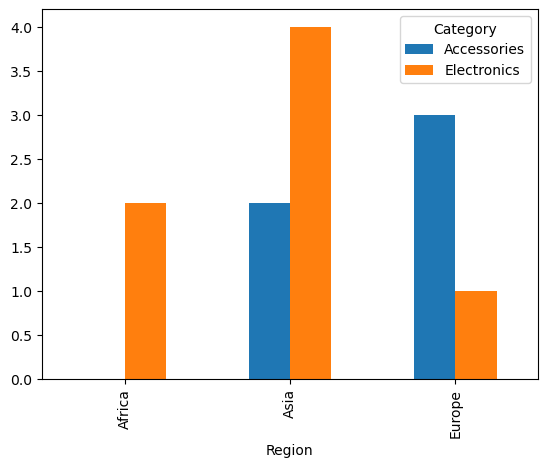

In [53]:
df_merged.value_counts(['Region','Category']).unstack().plot(kind='bar')

Q20

Normalize by index.

Convert into percentages.

In [55]:
pd.crosstab(df_merged['Region'], df_merged['Sales_Channel'], normalize='index') * 100

Sales_Channel,Offline,Online
Region,,
Africa,50.0,50.0
Asia,50.0,50.0
Europe,25.0,75.0


In [60]:
customer_index = customers.set_index('Customer_ID')

In [62]:
order_index = orders.set_index('Customer_ID')

In [64]:
customer_index

,Customer_Name,Region,Age
Customer_ID,,,
101,Alice,Asia,25
102,Bob,Europe,34
103,Charlie,Asia,29
104,David,Africa,45
105,Eva,Europe,31
106,Frank,Asia,40
107,Grace,Africa,27
108,Helen,Europe,36
